# 12 - Preprocessing, stationarity and decomposition

| | |
|---|---|
| **Milestone** | Milestone 2 |
| **Task** | M2-T2 (preprocessing and stationarity), M2-T3 (decomposition) |
| **Stage** | Stage 1 (data preparation) |
| **Aim** | Check every item for missing values, outliers and stationarity (ADF and KPSS together), and recommend how much to difference.<br>Decompose the totals and example items, and choose additive or multiplicative seasonality with a stated rule. |
| **Inputs** | `data/raw/sales_train_evaluation.csv`<br>`data/raw/calendar.csv`<br>`data/interim/{foods,hobbies,household}_candidates.csv`<br>`data/processed/breaks_by_origin.csv` |
| **Outputs** | `outputs/m2/tables/stationarity_items.csv`<br>`outputs/m2/tables/stationarity_summary.csv`<br>`outputs/m2/tables/stationarity_aggregates.csv`<br>`outputs/m2/tables/data_quality.csv`<br>`outputs/m2/tables/decomposition_choice.csv`<br>`outputs/m2/tables/demo_series.parquet`<br>`outputs/m2/tables/demo_decomposition.parquet`<br>`outputs/m2/figures/m2_*.png (7 figures)` |
| **Hypotheses** | none tested here; feeds the order choice for H1-H3 and the evidence for H4 |
| **Expected runtime** | about 2-4 min |

## 1. Setup and config

Shared paths and constants come from `src/config.py`.

In [1]:
import os, sys, warnings
sys.path.append("../src")
os.environ["PYTHONPATH"] = os.path.abspath("../src")
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.seasonal import seasonal_decompose, STL

from config import ROOT, RAW, INTERIM, PROCESSED, M2_TABLES, M2_FIGS, SEED, CATEGORIES, EVAL_ORIGINS, FIG_STYLE, make_dirs
from stationarity import check_series, count_outliers, outlier_cut, swing_rule, fix_christmas
from classical import draw_sample

make_dirs()
plt.rcParams.update(FIG_STYLE)
WRITTEN = []

## 2. Load data

The **trimmed** series are the Milestone 1 output (each item starts at its first sale). The raw file is read only to show what trimming removed and to check for empty cells.

In [2]:
long_df = pd.concat([pd.read_csv(INTERIM / f"{c}_candidates.csv", parse_dates=["date"])
                     for c in ["foods", "hobbies", "household"]], ignore_index=True)
long_df["category"] = long_df["item_id"].str.split("_").str[0]
calendar = pd.read_csv(RAW / "calendar.csv", parse_dates=["date"])
sales = pd.read_csv(RAW / "sales_train_evaluation.csv")
day_cols = [c for c in sales.columns if c.startswith("d_")]
ca_raw = sales[sales["state_id"] == "CA"].groupby("item_id")[day_cols].sum()
ca_raw.columns = calendar.set_index("d").loc[day_cols, "date"]

breaks = pd.read_csv(PROCESSED / "breaks_by_origin.csv", parse_dates=["origin"])
has_break = breaks[breaks["origin"].isin(EVAL_ORIGINS)].groupby("item_id")["has_break"].any()
sample = draw_sample(has_break, CATEGORIES)
examples = sample.groupby("category")["item_id"].apply(lambda s: list(s[:2])).sum()   # first two per category
print(long_df["item_id"].nunique(), "items; examples:", examples)

726 items; examples: ['FOODS_1_043', 'FOODS_1_085', 'HOBBIES_1_004', 'HOBBIES_1_005', 'HOUSEHOLD_1_019', 'HOUSEHOLD_1_040']


## 3. Method

**Missing values.** The sales file has no empty cells, but a product that is not on sale yet shows 0. Those leading zeros were trimmed in Milestone 1 (notebook 00b). Zeros *after* the first sale are real (stockouts, slow days) and are kept. We also check that no calendar day is missing inside a trimmed series.

**Outliers.** A day is flagged if it is above Q3 + 3 × IQR of that item's daily sales. We flag but do not change them: a promotion spike is real demand, and the models should see it.

**Stationarity.** ADF and KPSS ask opposite questions, so we use both. ADF's null is "unit root" (non-stationary); KPSS's null is "stationary". Each is run with a constant (`c`) and with a trend (`ct`) at the 5% level:

| Label | Rule |
|---|---|
| stationary | ADF(c) rejects and KPSS(c) does not |
| trend-stationary | KPSS(c) rejects, KPSS(ct) does not, ADF(ct) rejects |
| difference-stationary | KPSS(c) rejects and ADF(ct) does not |
| conflicting | anything else |

`d` comes from `ndiffs` (KPSS) and `D` from `nsdiffs` (OCSB, period 7). This is an **offline** diagnostic on each full series; the forecasting notebook recomputes d and D on data up to origin 0 only.

**Additive or multiplicative?** If the weekly swing (max − min within a week) grows with the weekly level (Spearman ρ ≥ 0.5, p < 0.05), the season scales with the level and multiplicative fits better; otherwise additive. We also compare the residual spread of both forms.

**Zeros and multiplicative models.** A multiplicative model divides by the level, so a single zero breaks it. Items: decomposed on sales + 1. Totals: almost never zero, except 25 December when stores close; that day is replaced by the mean of the same weekday a week before and after, **for decomposition only**.

## 4. Run

Data quality first, then the stationarity tests on all 726 items (in parallel) and the four totals.

In [3]:
gaps = long_df.groupby("item_id")["date"].apply(lambda d: (d.diff().dt.days.dropna() != 1).sum())
quality = []
for cat in CATEGORIES + ["ALL"]:
    ids = long_df["item_id"].unique() if cat == "ALL" else long_df.loc[long_df["category"] == cat, "item_id"].unique()
    g = long_df[long_df["item_id"].isin(ids)]
    raw = ca_raw.loc[ids]
    quality.append({"category": cat, "items": len(ids), "raw_empty_cells": int(raw.isna().sum().sum()),
                    "leading_zero_days_trimmed": int(raw.shape[0] * raw.shape[1] - len(g)),
                    "missing_days_inside_series": int(gaps.loc[ids].sum()),
                    "zero_days_kept_share": float((g["sales"] == 0).mean()),
                    "outlier_days": int(sum(count_outliers(x) for _, x in g.groupby("item_id")["sales"])),
                    "days_in_series": len(g)})
quality = pd.DataFrame(quality)
quality["outlier_share"] = quality["outlier_days"] / quality["days_in_series"]
quality.to_csv(M2_TABLES / "data_quality.csv", index=False)
WRITTEN.append(M2_TABLES / "data_quality.csv")
print(quality.round(4).to_string(index=False))

 category  items  raw_empty_cells  leading_zero_days_trimmed  missing_days_inside_series  zero_days_kept_share  outlier_days  days_in_series  outlier_share
    FOODS    337                0                      44914                           0                0.0802          1460          609203         0.0024
  HOBBIES    106                0                      12223                           0                0.0922           485          193523         0.0025
HOUSEHOLD    283                0                      62019                           0                0.0776           615          487284         0.0013
      ALL    726                0                     119156                           0                0.0810          2560         1290010         0.0020


In [4]:
# About 0.25 s per item, so a plain loop is fast enough (and avoids clashing with other joblib pools)
series = {i: g.sort_values("date")["sales"].to_numpy() for i, g in long_df.groupby("item_id")}
st = pd.DataFrame([{"item_id": i, **check_series(y)} for i, y in series.items()])
st["category"] = st["item_id"].str.split("_").str[0]
st.to_csv(M2_TABLES / "stationarity_items.csv", index=False)
WRITTEN.append(M2_TABLES / "stationarity_items.csv")

totals = {cat: long_df[long_df["category"] == cat].groupby("date")["sales"].sum() for cat in CATEGORIES}
totals["CA_TOTAL"] = long_df.groupby("date")["sales"].sum()
agg = pd.DataFrame([{"series": k, **check_series(v.to_numpy())} for k, v in totals.items()])
agg.to_csv(M2_TABLES / "stationarity_aggregates.csv", index=False)
WRITTEN.append(M2_TABLES / "stationarity_aggregates.csv")
print(agg.round(4).to_string(index=False))

   series  adf_c  kpss_c  adf_ct  kpss_ct                 label  d  D
    FOODS 0.1033    0.01  0.3360     0.01 difference-stationary  1  0
  HOBBIES 0.0333    0.01  0.0809     0.01 difference-stationary  1  0
HOUSEHOLD 0.2337    0.01  0.2974     0.01 difference-stationary  1  0
 CA_TOTAL 0.1276    0.01  0.3562     0.01 difference-stationary  1  0


## 5. Results

**Stationarity shares per category.**

 category  n_items  stationary  trend-stationary  difference-stationary  conflicting   d=0   d=1  d=2  D=1
    FOODS      337       0.187             0.116                  0.151        0.546 0.050 0.950  0.0  0.0
  HOBBIES      106       0.170             0.028                  0.123        0.679 0.047 0.953  0.0  0.0
HOUSEHOLD      283       0.148             0.067                  0.177        0.608 0.067 0.933  0.0  0.0
      ALL      726       0.169             0.084                  0.157        0.590 0.056 0.944  0.0  0.0


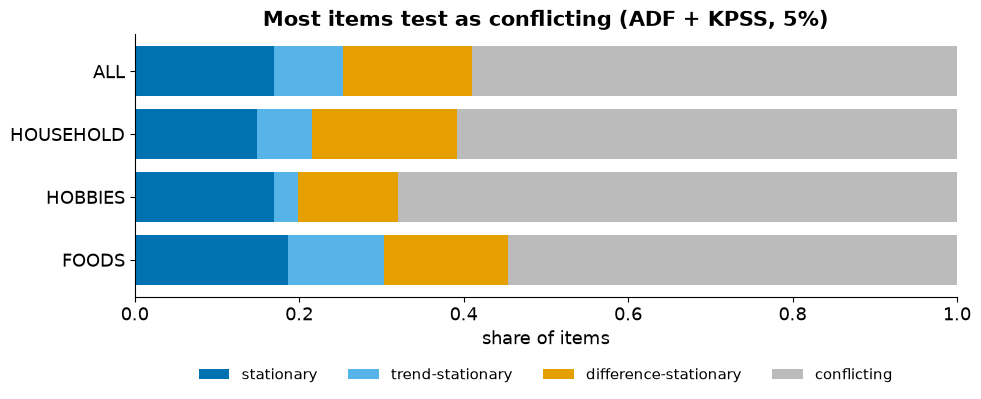

In [5]:
LABELS = ["stationary", "trend-stationary", "difference-stationary", "conflicting"]
rows = []
for cat in CATEGORIES + ["ALL"]:
    d = st if cat == "ALL" else st[st["category"] == cat]
    r = {"category": cat, "n_items": len(d)}
    for lab in LABELS:
        r[lab] = (d["label"] == lab).mean()
    for k in [0, 1, 2]:
        r[f"d={k}"] = (d["d"] == k).mean()
    r["D=1"] = (d["D"] == 1).mean()
    rows.append(r)
summary = pd.DataFrame(rows)
summary.to_csv(M2_TABLES / "stationarity_summary.csv", index=False)
WRITTEN.append(M2_TABLES / "stationarity_summary.csv")
print(summary.round(3).to_string(index=False))

fig, ax = plt.subplots(figsize=(10, 4.5))
left = np.zeros(4)
colors = ["#0072B2", "#56B4E9", "#E69F00", "#BBBBBB"]
cats = CATEGORIES + ["ALL"]
for lab, c in zip(LABELS, colors):
    vals = summary.set_index("category").loc[cats, lab].to_numpy()
    ax.barh(cats, vals, left=left, color=c, label=lab)
    left += vals
ax.set_xlim(0, 1)
ax.set_xlabel("share of items")
top = summary.set_index("category").loc["ALL", LABELS].idxmax()
ax.set_title(f"Most items test as {top} (ADF + KPSS, 5%)")
ax.legend(ncol=4, loc="lower center", bbox_to_anchor=(0.5, -0.38), frameon=False)
fig.tight_layout()
fig.savefig(M2_FIGS / "m2_stationarity_shares.png", bbox_inches="tight")
WRITTEN.append(M2_FIGS / "m2_stationarity_shares.png")
plt.show()

**ACF and PACF.** Last 730 days. Spikes at lags 7, 14, 21 are the weekly season.

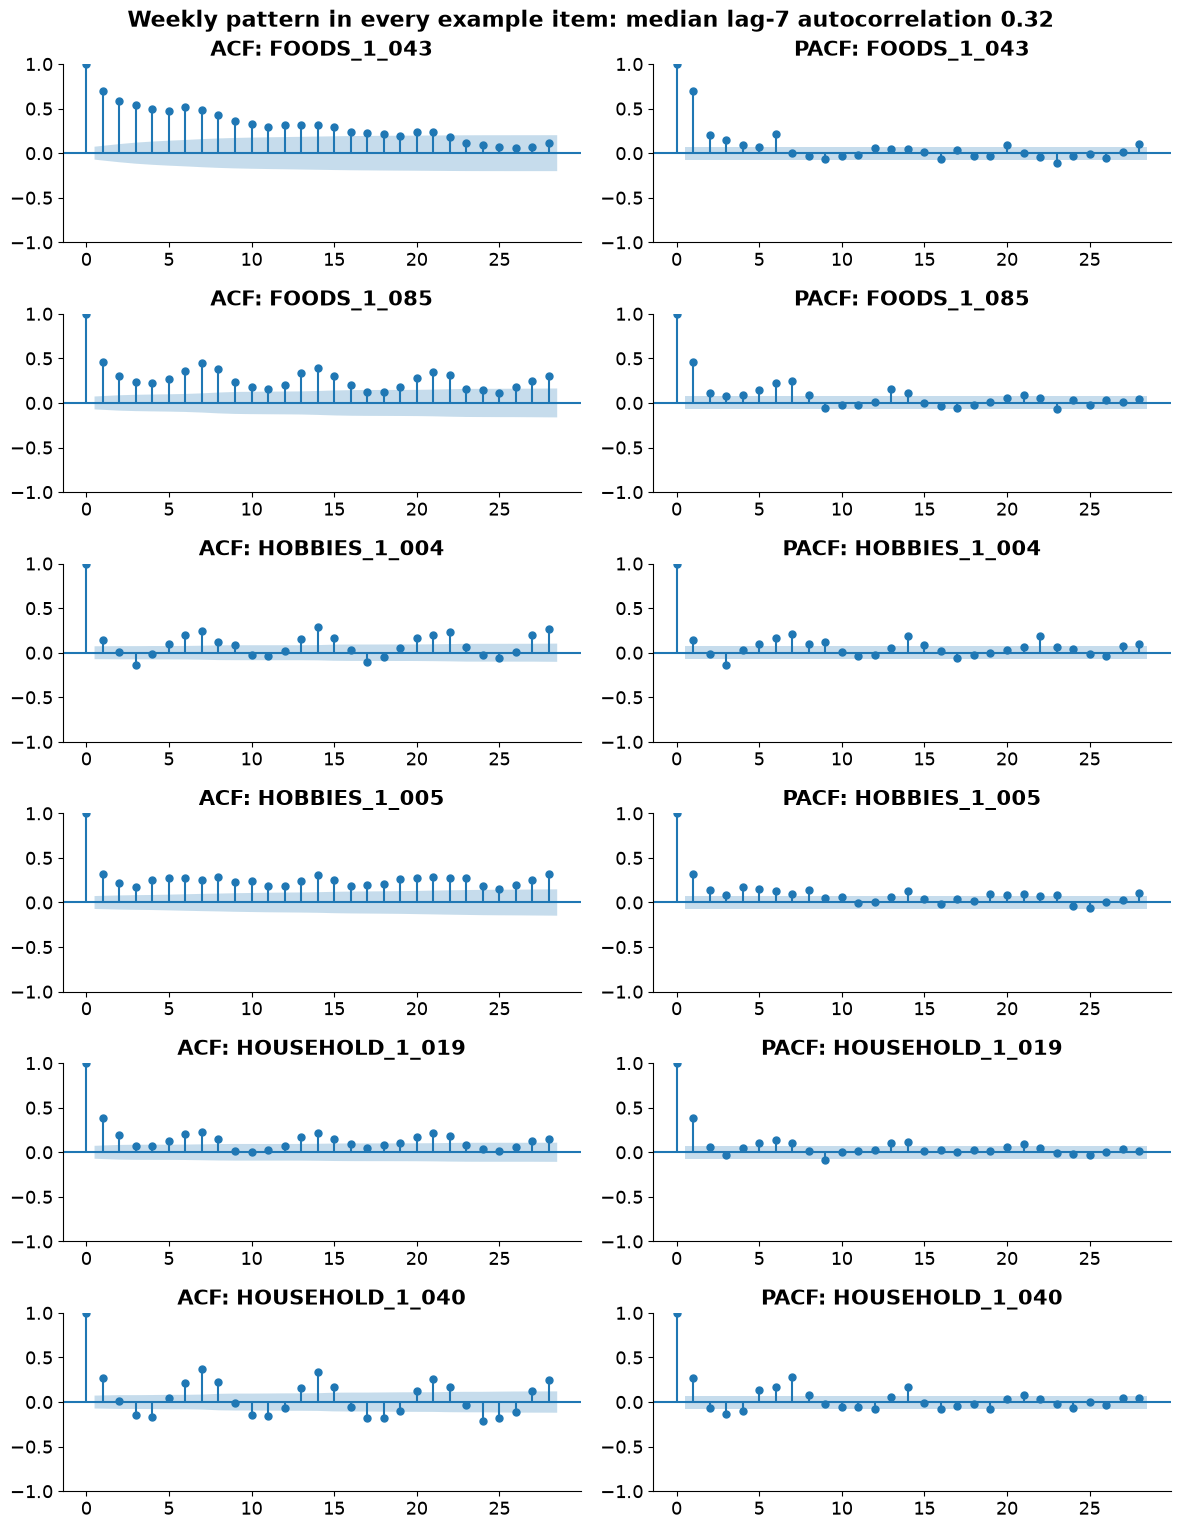

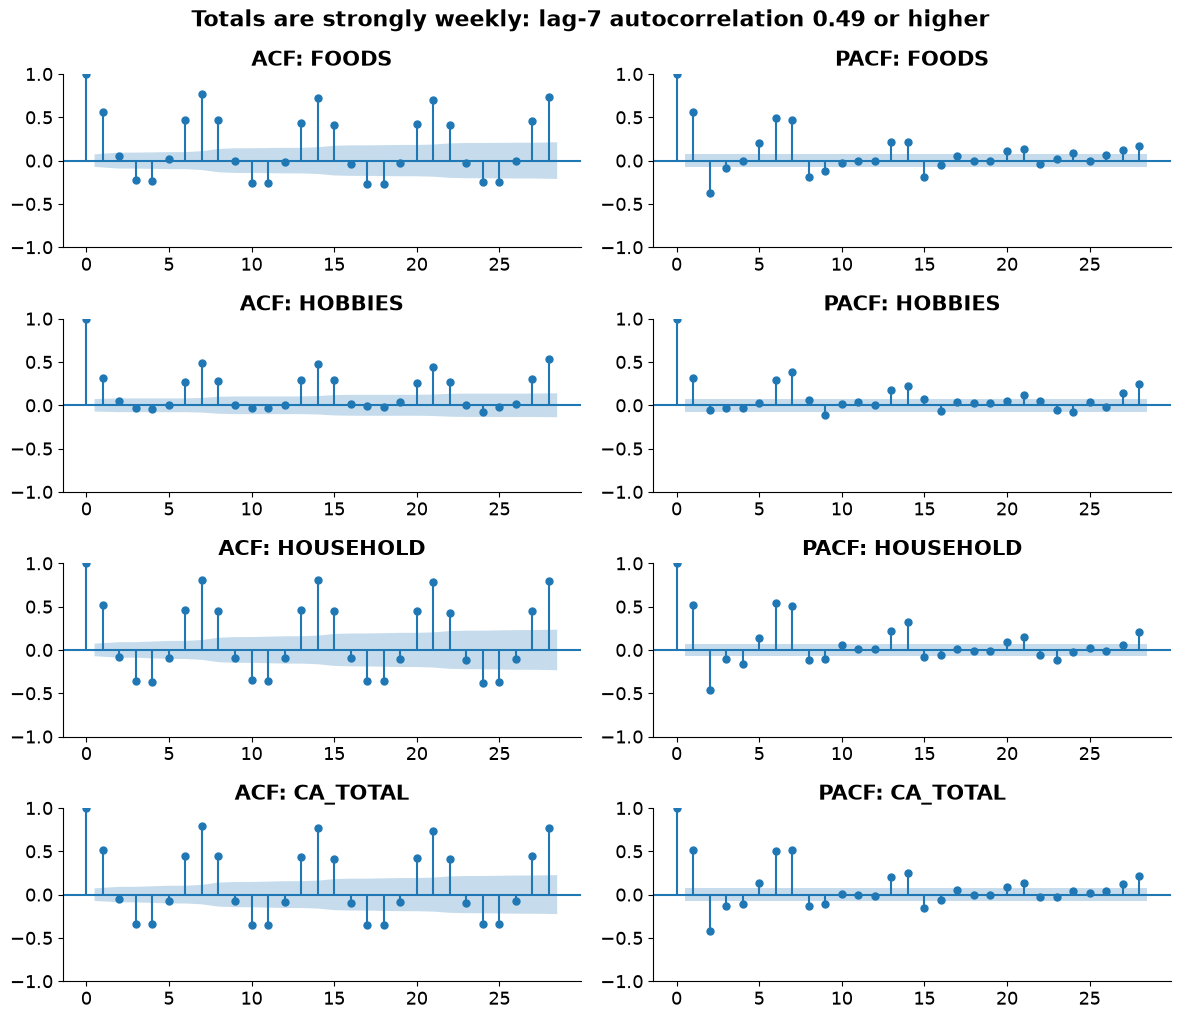

In [6]:
def acf_grid(named, fname, title):
    fig, axes = plt.subplots(len(named), 2, figsize=(12, 2.6 * len(named)))
    for row, (name, y) in zip(axes, named):
        plot_acf(y, lags=28, ax=row[0], title=f"ACF: {name}")
        plot_pacf(y, lags=28, ax=row[1], title=f"PACF: {name}", method="ywm")
    fig.suptitle(title, fontsize=16, fontweight="bold")
    fig.tight_layout()
    fig.savefig(M2_FIGS / fname)
    WRITTEN.append(M2_FIGS / fname)
    plt.show()

acf7 = lambda y: pd.Series(y).autocorr(7)
item_named = [(i, series[i][-730:]) for i in examples]
acf_grid(item_named, "m2_acf_pacf_items.png",
         f"Weekly pattern in every example item: median lag-7 autocorrelation {np.median([acf7(y) for _, y in item_named]):.2f}")
agg_named = [(k, v.to_numpy()[-730:]) for k, v in totals.items()]
acf_grid(agg_named, "m2_acf_pacf_aggregates.png",
         f"Totals are strongly weekly: lag-7 autocorrelation {min(acf7(y) for _, y in agg_named):.2f} or higher")

**Before and after differencing.** One item and the California total: the level, the first difference (removes a changing level) and the seasonal difference at lag 7 (removes the weekly pattern).

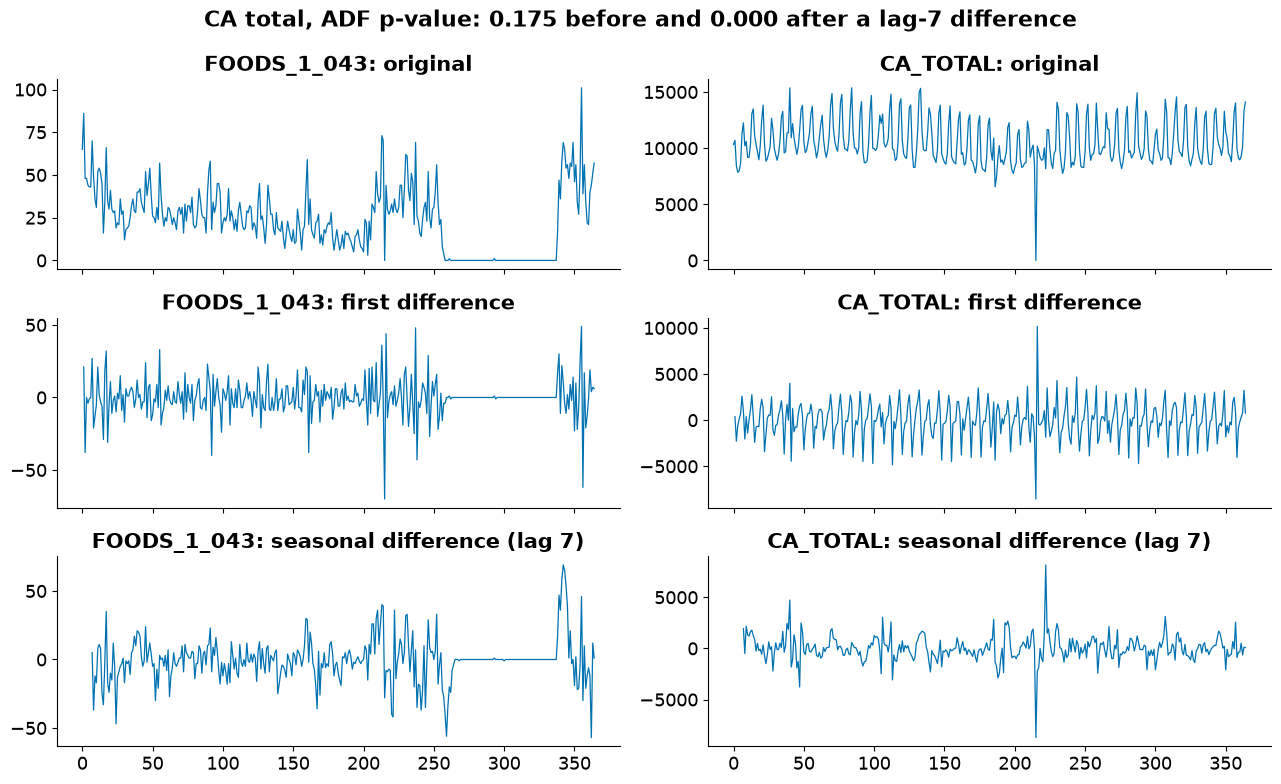

In [7]:
fig, axes = plt.subplots(3, 2, figsize=(13, 8), sharex="col")
for col, (name, y) in enumerate([(examples[0], pd.Series(series[examples[0]][-365:])),
                                 ("CA_TOTAL", pd.Series(totals["CA_TOTAL"].to_numpy()[-365:]))]):
    for row, (lab, z) in enumerate([("original", y), ("first difference", y.diff()), ("seasonal difference (lag 7)", y.diff(7))]):
        axes[row, col].plot(z.to_numpy(), lw=0.9, color="#0072B2")
        axes[row, col].set_title(f"{name}: {lab}")
from stationarity import adf_p
p_before = adf_p(totals["CA_TOTAL"].to_numpy()[-365:])
p_after = adf_p(totals["CA_TOTAL"].diff(7).dropna().to_numpy()[-365:])
fig.suptitle(f"CA total, ADF p-value: {p_before:.3f} before and {p_after:.3f} after a lag-7 difference",
             fontsize=16, fontweight="bold")
fig.tight_layout()
fig.savefig(M2_FIGS / "m2_differencing.png")
WRITTEN.append(M2_FIGS / "m2_differencing.png")
plt.show()

**Outliers.** Example: the item with the most flagged days, with its fence.

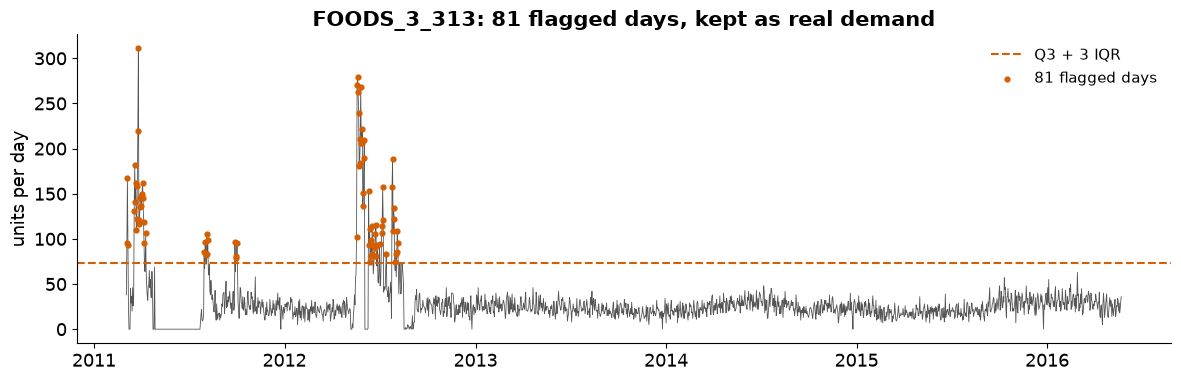

In [8]:
n_out = {i: count_outliers(y) for i, y in series.items()}
worst = max(n_out, key=n_out.get)
y = long_df[long_df["item_id"] == worst].set_index("date")["sales"]
fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(y.index, y, lw=0.6, color="#555555")
ax.axhline(outlier_cut(y), color="#D55E00", ls="--", label="Q3 + 3 IQR")
hi = y[y > outlier_cut(y)]
ax.scatter(hi.index, hi, color="#D55E00", s=12, zorder=3, label=f"{len(hi)} flagged days")
ax.set_title(f"{worst}: {len(hi)} flagged days, kept as real demand")
ax.set_ylabel("units per day")
ax.legend(frameon=False)
fig.tight_layout()
fig.savefig(M2_FIGS / "m2_outliers_example.png")
WRITTEN.append(M2_FIGS / "m2_outliers_example.png")
plt.show()

**Decomposition.** Classical additive, classical multiplicative (period 7) and STL, plus the choice rule.

In [9]:
def residual_spread(y, kind):
    """Residual sd (in units) divided by the mean, for one decomposition."""
    if kind == "stl":
        r = STL(y, period=7, robust=True).fit()
        resid = y - r.trend - r.seasonal
    else:
        d = seasonal_decompose(y, model=kind, period=7)
        fit = d.trend + d.seasonal if kind == "additive" else d.trend * d.seasonal
        resid = y - fit
    return float(np.nanstd(resid) / np.mean(y))

choice = []
for name, s in list(totals.items()) + [(i, long_df[long_df["item_id"] == i].set_index("date")["sales"]) for i in examples]:
    is_total = name in totals
    y = fix_christmas(s) if is_total else s + 1.0          # totals: Christmas fixed; items: +1 so division works
    rho, p, pick = swing_rule(y.index, y.to_numpy())
    choice.append({"series": name, "level": "total" if is_total else "item", "zero_handling": "Christmas replaced" if is_total else "sales + 1",
                   "zero_days": int((s == 0).sum()), "spearman_level_vs_swing": rho, "p_value": p, "rule_choice": pick,
                   "resid_cv_additive": residual_spread(y, "additive"), "resid_cv_multiplicative": residual_spread(y, "multiplicative"),
                   "resid_cv_stl": residual_spread(y, "stl")})
choice = pd.DataFrame(choice)
choice["lower_residual"] = np.where(choice["resid_cv_multiplicative"] < choice["resid_cv_additive"], "multiplicative", "additive")
choice.to_csv(M2_TABLES / "decomposition_choice.csv", index=False)
WRITTEN.append(M2_TABLES / "decomposition_choice.csv")
print(choice.round(4).to_string(index=False))

         series level      zero_handling  zero_days  spearman_level_vs_swing  p_value    rule_choice  resid_cv_additive  resid_cv_multiplicative  resid_cv_stl lower_residual
          FOODS total Christmas replaced          0                   0.3318   0.0000       additive             0.0710                   0.0698        0.0709 multiplicative
        HOBBIES total Christmas replaced          5                   0.2086   0.0005       additive             0.1182                   0.1179        0.1167 multiplicative
      HOUSEHOLD total Christmas replaced          5                   0.6179   0.0000 multiplicative             0.0855                   0.0763        0.0754 multiplicative
       CA_TOTAL total Christmas replaced          0                   0.3571   0.0000       additive             0.0664                   0.0648        0.0644 multiplicative
    FOODS_1_043  item          sales + 1        117                   0.5740   0.0000 multiplicative             0.3085           

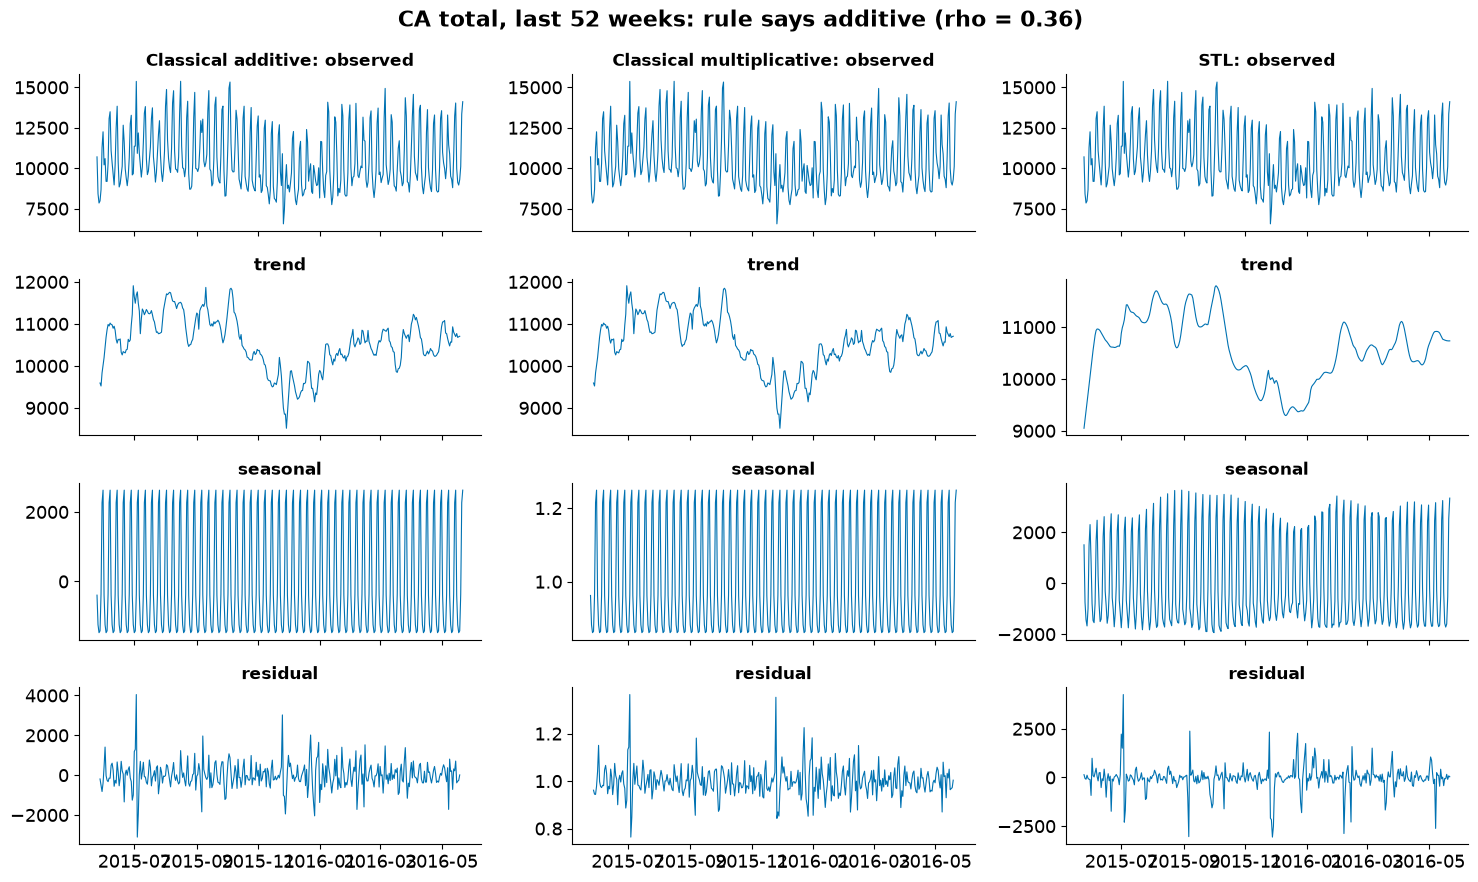

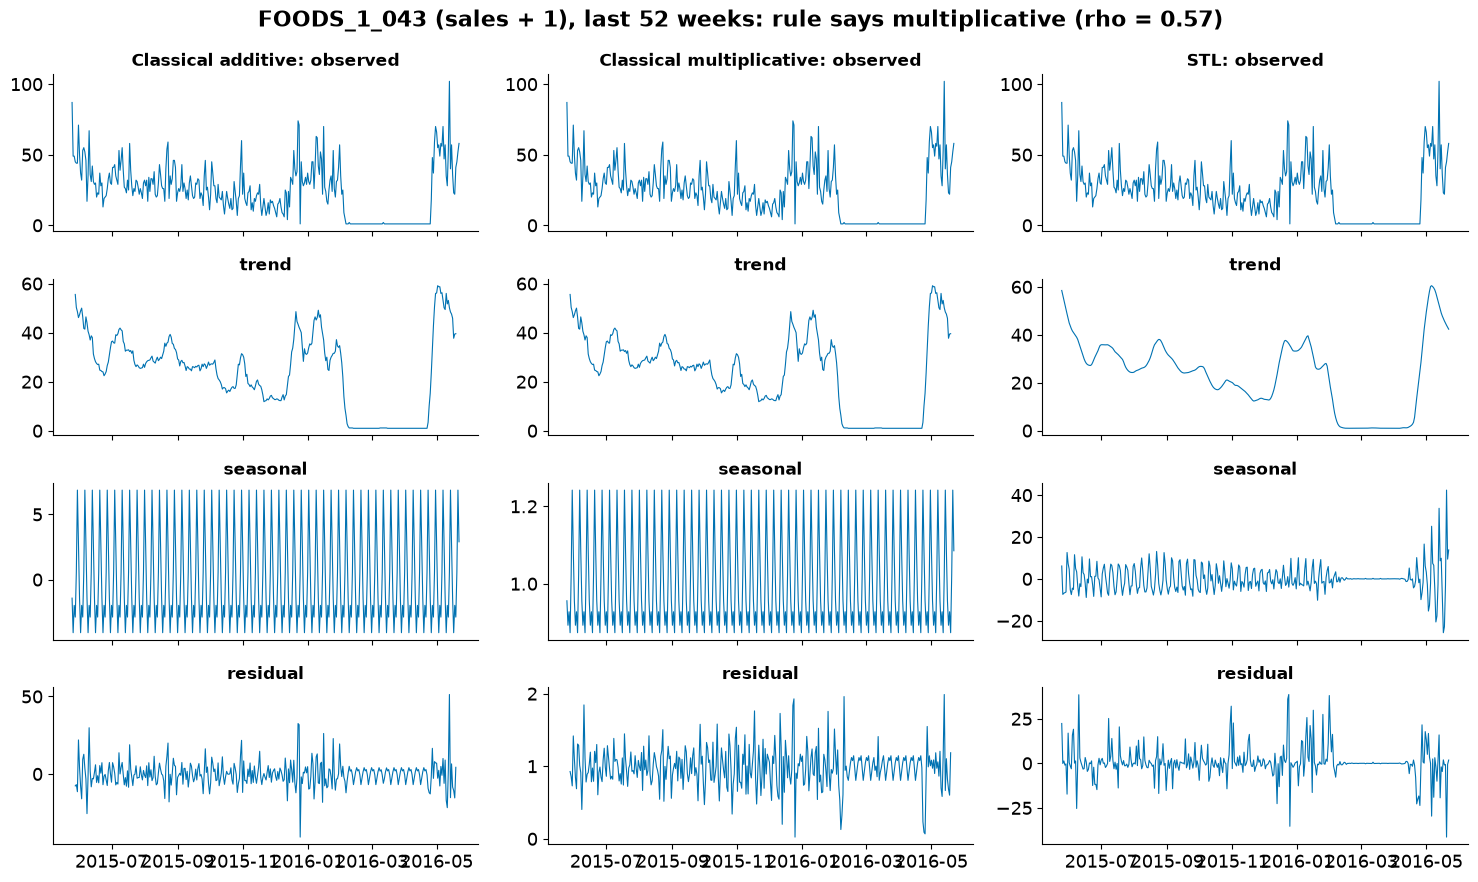

In [10]:
def decomp_figure(name, y, fname, title):
    y = y.iloc[-364:]
    add = seasonal_decompose(y, model="additive", period=7)
    mul = seasonal_decompose(y, model="multiplicative", period=7)
    stl = STL(y, period=7, robust=True).fit()
    fig, axes = plt.subplots(4, 3, figsize=(15, 9), sharex=True)
    for col, (lab, parts) in enumerate([("Classical additive", [add.observed, add.trend, add.seasonal, add.resid]),
                                        ("Classical multiplicative", [mul.observed, mul.trend, mul.seasonal, mul.resid]),
                                        ("STL", [y, stl.trend, stl.seasonal, stl.resid])]):
        for row, (part, z) in enumerate(zip(["observed", "trend", "seasonal", "residual"], parts)):
            axes[row, col].plot(z.index, z, lw=0.8, color="#0072B2")
            axes[row, col].set_title(f"{lab}: {part}" if row == 0 else part, fontsize=12)
    fig.suptitle(title, fontsize=16, fontweight="bold")
    fig.tight_layout()
    fig.savefig(M2_FIGS / fname)
    WRITTEN.append(M2_FIGS / fname)
    plt.show()

c = choice.set_index("series")
decomp_figure("CA_TOTAL", fix_christmas(totals["CA_TOTAL"]), "m2_decomposition_aggregate.png",
              f"CA total, last 52 weeks: rule says {c.loc['CA_TOTAL', 'rule_choice']} (rho = {c.loc['CA_TOTAL', 'spearman_level_vs_swing']:.2f})")
e0 = examples[0]
decomp_figure(e0, long_df[long_df["item_id"] == e0].set_index("date")["sales"] + 1.0, "m2_decomposition_item.png",
              f"{e0} (sales + 1), last 52 weeks: rule says {c.loc[e0, 'rule_choice']} (rho = {c.loc[e0, 'spearman_level_vs_swing']:.2f})")

**Dashboard files** for the demo walkthrough: raw and trimmed daily sales, and the STL parts, for the 150 sample items and the totals.

In [11]:
ids = sample["item_id"].tolist()
raw = ca_raw.loc[ids].stack().rename("sales_raw").reset_index()
raw.columns = ["item_id", "date", "sales_raw"]
first = long_df.groupby("item_id")["date"].min()
raw["kept_after_trim"] = raw["date"] >= raw["item_id"].map(first)
raw.to_parquet(M2_TABLES / "demo_series.parquet", index=False)
WRITTEN.append(M2_TABLES / "demo_series.parquet")

parts = []
for name in ids + list(totals):
    s = totals[name] if name in totals else long_df[long_df["item_id"] == name].set_index("date")["sales"].astype(float)
    s = (fix_christmas(s) if name in totals else s).iloc[-364:]
    r = STL(s, period=7, robust=True).fit()
    parts.append(pd.DataFrame({"series": name, "date": s.index, "observed": s.to_numpy(), "trend": r.trend.to_numpy(),
                               "seasonal": r.seasonal.to_numpy(), "resid": r.resid.to_numpy()}))
pd.concat(parts).to_parquet(M2_TABLES / "demo_decomposition.parquet", index=False)
WRITTEN.append(M2_TABLES / "demo_decomposition.parquet")
print(len(raw), "raw rows,", sum(len(p) for p in parts), "decomposition rows")

291150 raw rows, 56056 decomposition rows


## 6. Checks

Sanity checks on the outputs.

In [12]:
assert len(st) == 726 and st["label"].isin(LABELS).all()
assert np.isclose(summary.set_index("category").loc["ALL", LABELS].sum(), 1)
assert quality.loc[quality["category"] == "ALL", "raw_empty_cells"].iloc[0] == 0
assert quality.loc[quality["category"] == "ALL", "missing_days_inside_series"].iloc[0] == 0
# the Christmas fix only changes 25 December
ca, fixed = totals["CA_TOTAL"], fix_christmas(totals["CA_TOTAL"])
changed = ca.index[ca != fixed]
assert ((changed.month == 12) & (changed.day == 25)).all()
# the trimmed series start at the first sale, so their first day always has sales
assert (long_df.sort_values("date").groupby("item_id")["sales"].first() > 0).all()
print("all checks passed; Christmas days changed:", len(changed))

all checks passed; Christmas days changed: 5


## 7. Interpretation

**We expected** most items to be stationary, as the Milestone 1 ADF test said (85% of candidates).
**We found** that ADF and KPSS together tell a more careful story: only **16.9%** of the 726 items are cleanly stationary, 8.4% trend-stationary, 15.7% difference-stationary, and **59.0% conflicting**. 92% of the conflicts are the same pattern: ADF rejects a unit root *and* KPSS rejects a stable level. That is what a series looks like when it is stationary around a level that *shifts* from time to time, which is exactly the behaviour Milestone 1 studied. KPSS is also very sensitive on long series (about 1,900 days here).

* `ndiffs` recommends **d = 1 for 94%** of items; `nsdiffs` recommends **D = 0 for every item**. So the weekly season is handled by seasonal AR/MA terms, not by seasonal differencing (notebook 14 shows the fitted seasonal AR is close to 1).
* All four totals are difference-stationary.
* **Data quality:** no empty cells, no missing days inside any trimmed series; 8.1% of kept days are zero (real zeros); 0.2% of days are flagged as outliers and kept.
* **Decomposition:** the swing rule picks additive for FOODS, HOBBIES and the CA total, multiplicative for HOUSEHOLD and for 4 of the 6 example items. The residual spread barely differs between the two forms (for example 0.066 vs 0.065 for the CA total), so the choice matters little for these series; STL gives a similar spread.

## 8. What comes next

* Notebook **13** fits Holt-Winters, ARIMA and SARIMA, using d and D recomputed on the data up to origin 0.
* Notebook **14** checks the residuals of those fits against the models' assumptions.

In [13]:
# Files written by this notebook
for p in WRITTEN:
    print(p.relative_to(ROOT), f"{p.stat().st_size / 1e3:,.0f} KB")

outputs\m2\tables\data_quality.csv 0 KB
outputs\m2\tables\stationarity_items.csv 72 KB
outputs\m2\tables\stationarity_aggregates.csv 0 KB
outputs\m2\tables\stationarity_summary.csv 1 KB
outputs\m2\figures\m2_stationarity_shares.png 38 KB
outputs\m2\figures\m2_acf_pacf_items.png 226 KB
outputs\m2\figures\m2_acf_pacf_aggregates.png 150 KB
outputs\m2\figures\m2_differencing.png 327 KB
outputs\m2\figures\m2_outliers_example.png 104 KB
outputs\m2\tables\decomposition_choice.csv 2 KB
outputs\m2\figures\m2_decomposition_aggregate.png 508 KB
outputs\m2\figures\m2_decomposition_item.png 447 KB
outputs\m2\tables\demo_series.parquet 704 KB
outputs\m2\tables\demo_decomposition.parquet 1,757 KB
